**AICE Associate <font color=red>실전 모의고사 (문제)</font>** — AICE_Asso_004_실전형_회귀_농산물도매시세

### **출하 건 데이터를 활용한 <span style="color:darkgreen">kg당 도매가(원)</span> 예측**
---

- 도메인 : 농산물 도매 시세
- 목  표 : kg당 도매가(원)를 예측하는 인공지능모델 개발<br>
기상과 반입 물량에 따라 가격이 크게 출렁여 스마트산지의 매입 계획 수립이 어렵습니다.<br>
그래서 스마트산지 구매팀은 보유한 출하 건 데이터를 바탕으로 'kg당 도매가(원)(Price_Per_Kg)'을 예측하는 인공지능 모델을 도입하려고 합니다.<br>
스마트산지는 kg당 도매가(원) 예측 결과를 업무에 활용한다면 손실을 줄이고 서비스 품질을 높일 수 있을 것으로 보고 있습니다.<br>

---

#### **<span style="color:red">[유의사항]</span>**
- <span style="color:darkgreen">각 문항의 답안은 반드시 *'# 여기에 답안코드를 작성하고 실행하세요.', '# 아래의 코드를 정정하고 실행하세요.', '# 아래 코드의 빈칸을 채우고 실행하세요.'* 등이 표시된 셀(cell)에 입력해야 합니다</span>
- <span style="color:darkgreen">제공된 시험문항 셀을 삭제하거나 답안 위치가 아닌 다른 셀에 답안코드를 작성 시 채점되지 않습니다</span>
- 답안 작성 전에 문항에 제시된 가이드를 확인하세요
- 문항에 변수명이 제시된 경우 반드시 해당 변수명을 사용하세요. 앞 문항의 결과를 뒤 문항이 이어서 사용하므로 순서대로 실행하세요
- 답안 변수(`답안3`, `답안7_1` 등)가 있는 문항은 코드 셀 맨 아래 답안 변수에 값을 입력하세요(글자는 따옴표로 감싸기, 숫자는 문항이 안내한 자릿수로 반올림)
- 막히면 문항 아래 접혀 있는 **힌트**(1~3단계)를 차례로 펼쳐 보세요
- <font color=blue>**모든 문항을 풀고 맨 마지막 셀(전체 자동 채점)을 실행하면 문항별 점수와 총점이 나옵니다.** 채점은 실행한 결과(변수·답안·실행한 코드)로 합니다</font>
- <font color=blue>**오픈북은 허용된 사이트만 참고하세요**</font>
---

#### **[학습 정보]**
- 학습 목표 : 스마트산지의 데이터로 kg당 도매가(원)를 예측하는 AI 모델을 만들며 데이터 분석·전처리·모델링 전 과정을 수행할 수 있다
- AICE 역량 : 데이터 분석(DA1 분석 환경 구성, DA2 데이터 불러오기·구조 파악, DA3 탐색적 데이터 분석, DA4 데이터 시각화) / 데이터 전처리(DP1 이상치 처리, DP2 결측치 처리, DP3 인코딩·변수 변환, DP4 데이터 분할, DP5 스케일링) / AI 모델링(AM1 머신러닝 모델 학습·탐색, AM2 모델 해석, AM3 모델 성능 평가, AM4 딥러닝 모델 구성·학습, AM5 딥러닝 학습 결과 분석)
- 기술 스택 : pandas(import pandas as pd, read_csv, head, iloc, quantile, drop, reset_index, dropna, sum, isnull, get_dummies, info, Series, idxmax, columns, shape) · seaborn(boxplot, violinplot) · matplotlib(import matplotlib.pyplot as plt, subplots, show, plot, title, xlabel, ylabel, legend) · scikit-learn(train_test_split, MinMaxScaler, fit_transform, transform, RandomForestRegressor, fit, DecisionTreeRegressor, feature_importances_, score) · TensorFlow(Keras)(Sequential, EarlyStopping, compile, fit, Input, Dense, history)
- 난이도 : 공식형(중급) (설계 난이도 점수 2.55 / 5)
- 예상 소요 시간 : 약 121분 (문항별 시간은 각 문항 제목 아래)
- 관련 도메인 : 농산물 도매 시세 (농업·식품)

**[ 데이터 컬럼 설명 (데이터 파일명: data.csv) ]**

- Price_Per_Kg          : kg당 도매가(원)
- E_Row_Id              : 행 식별번호
- FE_Rainfall_Mm        : 최근 4주 강수량(mm)
- FE_Sunshine_H         : 최근 4주 일조시간(h)
- FE_Supply_Ton         : 반입 물량(톤)
- FE_Stock_Ton          : 저장 재고(톤)
- FE_Import_Ton         : 수입 물량(톤)
- FE_Demand_Idx         : 수요 지수
- FE_Holiday_Days       : 인접 공휴일 수
- E_Item                : 품목
- E_Origin              : 산지
- E_Grade               : 등급
- E_Market              : 도매시장

## <font color=blue>**<데이터 분석 (20점)>**</font>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요.**

In [1]:
import numpy as np
import seaborn as sns

### **1. 그래프 시각화를 위해 matplotlib 라이브러리를 사용하려고 합니다. 아래 가이드의 별칭(alias)으로 불러오세요.**

<sub>학습 목표: 분석에 필요한 파이썬 라이브러리를 관용 별칭으로 불러올 수 있다 | 역량: DA1 분석 환경 구성 | 기술: matplotlib(import matplotlib.pyplot as plt) | 난이도: 기초 | 예상 시간: 4분</sub>

- 제시된 가이드에 맞춰 코드를 작성하고 실행하세요
    - 사용할 라이브러리 : `matplotlib.pyplot`
    - 별칭(alias) : `plt`
- **[코드 채점]** 답안 셀에 작성한 코드(함수·인자)를 채점합니다 — 셀 맨 위 `# [N번 문항]` 주석은 지우지 말고, 셀을 꼭 실행하세요
- 배점 : 5점

---

In [2]:
# [1번 문항] 여기에 답안코드를 작성하고 실행하세요.
import matplotlib.pyplot as plt

<details><summary>힌트 1단계 (접근 방향) - 1번 문항</summary>

`import 라이브러리 as 별칭` 문법으로 라이브러리를 불러옵니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 1번 문항</summary>

사용할 도구: `import ... as ...`.

</details>

<details><summary>힌트 3단계 (코드 구조) - 1번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
import ____ as ____

# ▷ 필요한 도구를 불러오기(가이드에 적힌 라이브러리)
```

</details>

### **2. AI 모델링을 위해 분석 및 처리할 데이터 파일을 읽어오려고 합니다. pandas로 데이터 파일을 읽어온 뒤, 데이터프레임 변수명 data 에 할당하고 첫 3개 행을 출력하세요.**

<sub>학습 목표: CSV 파일을 데이터프레임으로 읽고 행·열 구성을 확인할 수 있다 | 역량: DA2 데이터 불러오기·구조 파악 | 기술: pandas(import pandas as pd, read_csv, head) | 난이도: 기초 | 예상 시간: 4분</sub>

- 제시된 가이드에 맞춰 코드를 작성하고 실행하세요
    - 데이터프레임 변수명 : data
    - 경로 없이 파일 이름만으로 읽을 수 있습니다
    - 대상 파일 : data.csv
- **[결과 변수]** 결과는 반드시 `data` 변수에 저장하세요 — 변수의 내용(모양·값)으로 채점합니다
- 확인 : 코드 셀 맨 아래 확인 줄(`print(data.shape)`)을 실행하세요.
- 참고: `shape[0]` 은 **행 수**, `shape[1]` 은 **열 수** 입니다
- 배점 : 5점

---

In [5]:
# [2번 문항] 여기에 답안코드를 작성하고 실행하세요.
import pandas as pd
data = pd.read_csv('data.csv')
data.head(3)
print(data.shape)

(1723, 13)


<details><summary>힌트 1단계 (접근 방향) - 2번 문항</summary>

파일 형식(csv/json/구분자)에 맞는 pandas 읽기 함수와 옵션을 고르세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 2번 문항</summary>

사용할 도구: `pd.read_csv`.

</details>

<details><summary>힌트 3단계 (코드 구조) - 2번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
import ____ as ____

data = pd.____('____')
# ▷ 가이드의 다음 단계를 작성

# [data] 결과 확인
# ▷ 가이드의 다음 단계를 작성
```
- 참고 문서: <https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html>

</details>

### **3. 시각화를 통해 품목(E_Item)와(과) 저장 재고(톤)(FE_Stock_Ton)의 분포와 관계를 파악할 계획입니다.**

<sub>학습 목표: 그래프로 변수의 분포와 관계를 시각화할 수 있다 | 역량: DA4 데이터 시각화 | 기술: seaborn(boxplot, violinplot) · matplotlib(subplots, show) | 난이도: 보통 | 예상 시간: 8분</sub>

- 앞 문항 결과 사용 : 1번 `plt` · 2번 `data`
- 대상 데이터프레임 : data
- 품목(E_Item) 별 저장 재고(톤)(FE_Stock_Ton)의 boxplot와 violinplot를 subplots를 활용해 가로 방향으로 나란히 그립니다
- 두 그래프의 제목을 각각 'Left Chart'와 'Distribution B'로 설정합니다
- **[코드 채점]** 답안 셀에 작성한 코드(함수·인자)를 채점합니다 — 셀 맨 위 `# [N번 문항]` 주석은 지우지 말고, 셀을 꼭 실행하세요
- 배점 : 5점

---

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48176 (\N{HANGUL SYLLABLE BAE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 52628 (\N{HANGUL SYLLABLE CU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49324 (\N{HANGUL SYLLABLE SA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44284 (\N{HANGUL SYLLABLE GWA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50577 (\N{HANGUL SYLLABLE YANG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/l

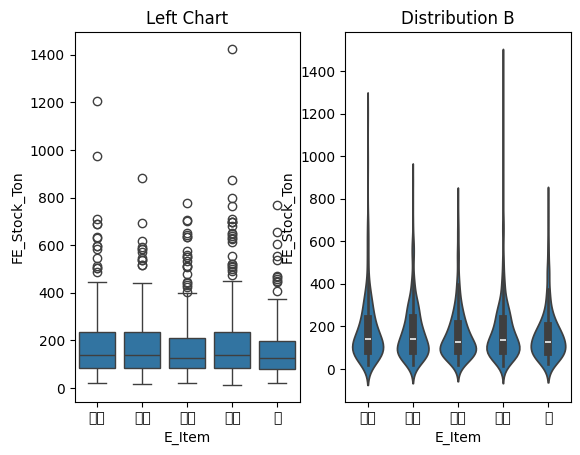

In [67]:
# [3번 문항] 여기에 답안코드를 작성하고 실행하세요.

fig, axes = plt.subplots(nrows=1, ncols=2)

sns.boxplot(data=data, x='E_Item', y='FE_Stock_Ton', ax=axes[0])
sns.violinplot(data=data, x='E_Item', y='FE_Stock_Ton', ax=axes[1])

axes[0].set_title('Left Chart')
axes[1].set_title('Distribution B')

plt.show()


<details><summary>힌트 1단계 (접근 방향) - 3번 문항</summary>

빈칸의 정답을 먼저 채워 코드 전체를 실행하세요. **개념** boxplot 은 중앙값·사분위·이상치를, violinplot 은 분포의 밀도 모양까지 보여 줍니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 3번 문항</summary>

사용할 도구: `plt.subplots`, `sns.boxplot`, `sns.violinplot`.

</details>

<details><summary>힌트 3단계 (코드 구조) - 3번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
import ____ as ____
import ____ as ____

fig, axes = plt.____(nrows=____, ncols=____, figsize=(____, ____))

sns.____(data=data, x='____', y='____', ax=axes[____])
sns.____(data=data, x='____', y='____', ax=axes[____])

axes[____].____('____')
axes[____].____('____')

# ▷ 가이드의 다음 단계를 작성

# ▷ `(fig, axes)` 에 결과를 저장 — `____` 사용

# ▷ 실행해서 결과 확인 — `boxplot` 사용
# ▷ 실행해서 결과 확인 — `____` 사용

# ▷ 실행해서 결과 확인 — `set_title` 사용
# ▷ 실행해서 결과 확인 — `set_title` 사용

# ▷ 가이드의 다음 단계를 작성
```
- 참고 문서: <https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html>
- 참고 문서: <https://seaborn.pydata.org/generated/seaborn.boxplot.html>
- 참고 문서: <https://seaborn.pydata.org/generated/seaborn.violinplot.html>

</details>

### **4. 컬럼 이름이 아니라 **위치 번호**로 데이터를 선택할 계획입니다. iloc 를 활용하십시오.**

<sub>학습 목표: 집계·통계량으로 데이터의 특징을 탐색할 수 있다 | 역량: DA3 탐색적 데이터 분석 | 기술: pandas(iloc) | 난이도: 쉬움 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 2번 `data`
- data 에서 행 위치 24, 열 위치 2 (둘 다 0부터 시작)의 값을 `iloc` 로 선택해 `cell` 에 담으세요
    - 이어서 첫 5개 행, 첫 3개 열만 `iloc` 슬라이싱으로 선택해 `sub` 에 보관하세요
- **[답안4]** `cell` 의 값을 **소수점 둘째 자리까지** 입력하세요
- 답안 : **[답안4]** 의 값만 코드 셀 맨 아래에 `답안4 = 값` 형태로 입력하세요
- 배점 : 5점

---

In [20]:
# [4번 문항] 여기에 답안코드를 작성하고 실행하세요.

cell = data.iloc[24, 2]
sub = data.iloc[:5, :3]

round(cell, 2)

답안4 = 41.8

<details><summary>힌트 1단계 (접근 방향) - 4번 문항</summary>

위치 기반 선택에는 iloc 를 쓰고, 슬라이스는 `시작:끝` 형태입니다. cell 값을 반올림하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 4번 문항</summary>

사용할 도구: `iloc`, `round`.

</details>

<details><summary>힌트 3단계 (코드 구조) - 4번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
cell = data.iloc[____, ____]
# ▷ `sub` 에 결과를 저장

# [답안4] 실행한 결과를 입력하세요
# ▷ 가이드의 다음 단계를 작성
```

</details>

## <font color=blue>**<데이터 전처리 (30점)>**</font>

### **5. 그래프로 확인한 결과, 반입 물량(톤)(FE_Supply_Ton) 컬럼에서 이상치가 발견되었습니다. AI모델링할 때 부정적 영향이 없도록 아래 안내대로 이상치를 처리하세요.**

<sub>학습 목표: 사분위 범위(IQR) 등의 기준으로 이상치를 찾아 처리할 수 있다 | 역량: DP1 이상치 처리 | 기술: pandas(quantile, drop, reset_index) | 난이도: 쉬움 | 예상 시간: 8분</sub>

- 앞 문항 결과 사용 : 2번 `data`
- 제시된 가이드에 맞춰 코드를 작성하고 실행하세요
    - 대상 데이터프레임 : data
    - ① 이상치 행 삭제 — 반입 물량(톤)(FE_Supply_Ton)이(가) upper fence 값보다 크거나 lower fence 값보다 작은 이상치 행(row)을 삭제하세요 (**IQR 배수 K = 2.0** — Q1 − K×IQR 보다 작거나 Q3 + K×IQR 보다 큰 값이 이상치)
    - ② 식별번호 열 삭제 — AI모델링에 불필요한 행 식별번호(E_Row_Id) 컬럼을 삭제하세요
    - 전처리를 적용한 데이터프레임은 data_temp 라는 변수명으로 저장하세요
- **[결과 변수]** 결과는 반드시 `data_temp` 변수에 저장하세요 — 변수의 내용(모양·값)으로 채점합니다
- 확인 : 코드 셀 맨 아래 확인 줄(`print(data_temp.shape)`)을 실행하세요.
- 배점 : 6점

---

In [55]:
# [5번 문항] 여기에 답안코드를 작성하고 실행하세요.

q1 = data['FE_Supply_Ton'].quantile(0.25)
q3 = data['FE_Supply_Ton'].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 2.0 * iqr
upper_fence = q3 + 2.0 * iqr

data_temp = data.drop(data[(data['FE_Supply_Ton'] < lower_fence) | (data['FE_Supply_Ton'] > upper_fence)].index)
data_temp = data_temp.drop('E_Row_Id', axis=1)
data_temp = data_temp.reset_index(drop=True)

print(data_temp.shape)

(1645, 12)


<details><summary>힌트 1단계 (접근 방향) - 5번 문항</summary>

빈칸을 채워 코드를 완성한 뒤 실행하세요. **개념** `quantile(0.25)` 는 1사분위수(Q1), `quantile(0.75)` 는 3사분위수(Q3), IQR = Q3 − Q1 입니다. 행을 지운 뒤 `reset_index(drop=True)` 로 번호를 0부터 다시 매기고, 옛 인덱스는 컬럼으로 남기지 않습니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 5번 문항</summary>

사용할 도구: `drop`, `quantile`, `reset_index`.

</details>

<details><summary>힌트 3단계 (코드 구조) - 5번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
q1 = data['____'].____(____)
q3 = data['____'].____(____)
iqr = q3 - q1

lower_fence = q1 - ____ * iqr
# ▷ `upper_fence` 에 결과를 저장

# ▷ `data_temp` 에 결과를 저장 — `drop` 사용
# ▷ `data_temp` 에 결과를 저장 — `drop` 사용
# ▷ 실행해서 결과 확인 — `reset_index` 사용

# [data_temp] 결과 확인
# ▷ 가이드의 다음 단계를 작성
```
- 참고 문서: <https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.quantile.html>
- 참고 문서: <https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.drop.html>
- 참고 문서: <https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.reset_index.html>

</details>

### **6. 데이터에 결측치가 있을 경우 AI모델링의 성능이 저하될 수 있습니다. AI모델링할 때 부정적 영향이 없도록 다음 지침에 따라 결측치를 처리하세요.**

<sub>학습 목표: 결측치를 확인하고 삭제하거나 대체할 수 있다 | 역량: DP2 결측치 처리 | 기술: pandas(dropna, sum, isnull) | 난이도: 쉬움 | 예상 시간: 8분</sub>

- 앞 문항 결과 사용 : 5번 `data_temp`
- 제시된 가이드에 맞춰 코드를 작성하고 실행하세요
    - 대상 데이터프레임 : data_temp
    - 결측치 개수를 확인한 후에 결측치가 있는 행을 모두 삭제하세요
    - 전처리가 반영된 데이터프레임은 변수명 data_na 에 담으세요
    - 결측치가 사라졌는지 확인하세요
- **[결과 변수]** 결과는 반드시 `data_na` 변수에 저장하세요 — 변수의 내용(모양·값)으로 채점합니다
- 확인 : 코드 셀 맨 아래 확인 줄(`print(data_na.shape)`)을 실행하세요.
- 배점 : 6점

---

In [56]:
# [6번 문항] 여기에 답안코드를 작성하고 실행하세요.

data_na = data_temp.dropna()

print(data_na.shape)

(1314, 12)


<details><summary>힌트 1단계 (접근 방향) - 6번 문항</summary>

빈칸을 채워 코드를 완성한 뒤 실행하세요. **개념** 결측치는 `isnull().sum()` 으로 세고, `dropna()` 로 행을 지우거나 `fillna()` 로 채웁니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 6번 문항</summary>

사용할 도구: `isnull`, `sum`, `dropna`.

</details>

<details><summary>힌트 3단계 (코드 구조) - 6번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
print( '____', data_temp.____().____() )
data_na = data_temp.____()
# ▷ 실행해서 결과 확인 — `sum`, `isnull` 사용

# [data_na] 결과 확인
# ▷ 가이드의 다음 단계를 작성
```
- 참고 문서: <https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sum.html>
- 참고 문서: <https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isnull.html>
- 참고 문서: <https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.dropna.html>

</details>

### **7. 반입 물량(톤)(FE_Supply_Ton)와(과) 최근 4주 일조시간(h)(FE_Sunshine_H)를 조합한 파생 변수를 만들어 모델 입력으로 활용할 계획입니다.**

<sub>학습 목표: 범주형 변수를 인코딩하고 변수를 정리·변환할 수 있다 | 역량: DP3 인코딩·변수 변환 | 기술: pandas(get_dummies, info) | 난이도: 쉬움 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 2번 `pd` · 6번 `data_na`
- 대상 데이터프레임 : data_na
- `FE_Supply_Ton` 를 (`FE_Sunshine_H` 의 절댓값 + 1) 로 나눈 값을 새 컬럼 `ratio_feature` 로 추가하세요
- 남은 문자열 컬럼 E_Item, E_Origin, E_Grade, E_Market 을(를) 범주형 컬럼을 0/1 컬럼으로 바꾸는(원-핫 인코딩) 함수(첫 번째 범주 열을 빼는 옵션=True)로 인코딩해 data_preset 에 담으세요
- 아래 코드 셀의 빈칸 `< blank07_1 >`, `< blank07_2 >`, `< blank07_3 >` 를 채우고 실행하세요
- 빈칸에 들어갈 내용(함수·인자·모듈 이름)을 코드 셀 맨 아래 `답안7_1`, `답안7_2`, `답안7_3` 변수에 각각 저장하세요
    - 예시) 답안7_0 = 'data'
- 배점 : 6점

---

In [57]:
# [7번 문항] 아래 코드의 빈칸을 채우고 실행하세요.

data_na['ratio_feature'] = data_na['FE_Supply_Ton'] / (data_na['FE_Sunshine_H'].abs() + 1)

data_preset = pd.get_dummies(data=data_na, columns=['E_Item', 'E_Origin', 'E_Grade', 'E_Market'], drop_first=True)
data_preset.info()

답안7_1 = 'get_dummies'
답안7_2 = 'drop_first'
답안7_3 = 'info'

<class 'pandas.core.frame.DataFrame'>
Index: 1314 entries, 1 to 1644
Data columns (total 22 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Price_Per_Kg     1314 non-null   float64
 1   FE_Rainfall_Mm   1314 non-null   float64
 2   FE_Sunshine_H    1314 non-null   float64
 3   FE_Supply_Ton    1314 non-null   float64
 4   FE_Stock_Ton     1314 non-null   float64
 5   FE_Import_Ton    1314 non-null   float64
 6   FE_Demand_Idx    1314 non-null   float64
 7   FE_Holiday_Days  1314 non-null   float64
 8   ratio_feature    1314 non-null   float64
 9   E_Item_무         1314 non-null   bool   
 10  E_Item_배추        1314 non-null   bool   
 11  E_Item_사과        1314 non-null   bool   
 12  E_Item_양파        1314 non-null   bool   
 13  E_Origin_영남      1314 non-null   bool   
 14  E_Origin_제주      1314 non-null   bool   
 15  E_Origin_충청      1314 non-null   bool   
 16  E_Origin_호남      1314 non-null   bool   
 17  E_Grade_중        13

/tmp/ipykernel_508/229667146.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_na['ratio_feature'] = data_na['FE_Supply_Ton'] / (data_na['FE_Sunshine_H'].abs() + 1)


<details><summary>힌트 1단계 (접근 방향) - 7번 문항</summary>

두 컬럼의 값을 행 단위로 나눠 새 컬럼에 저장합니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요. **개념** 원-핫 인코딩은 범주를 0/1 컬럼으로 바꿉니다(`첫 번째 범주 열을 빼는 옵션=True` 면 범주마다 첫 컬럼 하나를 뺍니다).

</details>

<details><summary>힌트 2단계 (사용할 도구) - 7번 문항</summary>

빈칸에 들어갈 것은 pandas(데이터프레임·시리즈 메서드) 쪽 이름입니다. 공식 문서 목록에서 찾아보세요: [pandas](https://pandas.pydata.org/docs/reference/index.html)

</details>

<details><summary>힌트 3단계 (코드 구조) - 7번 문항</summary>

코드 구조입니다. `____` 자리에 들어갈 이름은 아래 공식 문서에서 확인하세요(오픈북 사이트).
```python
data_na['ratio_feature'] = data_na['FE_Supply_Ton'] / (data_na['FE_Sunshine_H'].abs() + 1)

data_preset = pd.____(data=data_na, columns=['E_Item', 'E_Origin', 'E_Grade', 'E_Market'], ____=True)
data_preset.____()

답안7_1 = '____'   # 빈칸 1에 넣은 이름
답안7_2 = '____'   # 빈칸 2에 넣은 이름
답안7_3 = '____'   # 빈칸 3에 넣은 이름
```
- 참고 문서: <https://pandas.pydata.org/docs/reference/api/pandas.get_dummies.html>
- 참고 문서: <https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.info.html>

</details>

### **8. 훈련과 검증 데이터셋을 분리하고, 분리된 데이터의 크기를 확인할 계획입니다.**

<sub>학습 목표: 피처와 레이블을 나누고 훈련·검증 데이터로 분할할 수 있다 | 역량: DP4 데이터 분할 | 기술: pandas(drop) · scikit-learn(train_test_split) | 난이도: 쉬움 | 예상 시간: 8분</sub>

- 앞 문항 결과 사용 : 7번 `data_preset`
- 다음 지침에 따라 코드를 작성하고 실행하세요
    - 대상 데이터프레임 : data_preset
    - kg당 도매가(원)(Price_Per_Kg) 컬럼을 레이블값 y 로, 나머지 컬럼을 피처값 X 로 지정하세요
    - 반환값을 담을 변수 : X_train(훈련 피처), X_valid(검증 피처), y_train(훈련 레이블), y_valid(검증 레이블)
    - train_test_split 함수(scikit-learn)로 나누세요
    - random_state 는 100 로 고정하세요
    - 훈련 70%, 검증 30% 비율로 나누세요 (test_size=0.3)
- **[결과 변수]** 결과는 반드시 `X_valid` 변수에 저장하세요 — 변수의 내용(모양·값)으로 채점합니다
- 확인 : 코드 셀 맨 아래 확인 줄(`print(len(X_valid))`)을 실행하세요.
- 배점 : 6점

---

In [58]:
# [8번 문항] 여기에 답안코드를 작성하고 실행하세요.

from sklearn.model_selection import train_test_split

X = data_preset.drop('Price_Per_Kg', axis=1)
y = data_preset['Price_Per_Kg']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.3, random_state=100)

print(len(X_valid))

395


<details><summary>힌트 1단계 (접근 방향) - 8번 문항</summary>

피처와 레이블을 나눈 뒤, 훈련/검증으로 무작위 분할합니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 8번 문항</summary>

사용할 도구: `train_test_split`, `drop`.

</details>

<details><summary>힌트 3단계 (코드 구조) - 8번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
from sklearn.model_selection import ____

X = data_preset.____('____', axis=____)
# ▷ `y` 에 결과를 저장

# ▷ `(X_train, X_valid, y_train, y_valid)` 에 결과를 저장 — `train_test_split` 사용

# [X_valid] 결과 확인
# ▷ 가이드의 다음 단계를 작성
```
- 참고 문서: <https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.drop.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html>

</details>

### **9. 스케일링을 통해 변수들의 단위(범위) 차이가 모델에 미치는 영향을 줄이려 합니다. (최솟값 0~최댓값 1 정규화)**

<sub>학습 목표: 훈련 데이터로 스케일러를 학습해 검증 데이터에 같은 기준을 적용할 수 있다 | 역량: DP5 스케일링 | 기술: scikit-learn(MinMaxScaler, fit_transform, transform) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `X_train`, `X_valid`
- 제시된 가이드에 맞춰 스케일링 처리하는데 오류가 발생하고 있습니다. 코드의 오류를 바로잡으세요
    - sklearn.preprocessing 에서 MinMaxScaler 를 import 하세요
    - MinMaxScaler 를 scaler 변수에 설정하세요
    - 훈련 데이터(X_train)에 대해 스케일러를 학습시키고 변환을 적용해 X_train 에 다시 보관하세요
    - 검증 데이터(X_valid)에는 **학습된 기준을 그대로** 적용(변환만)해 X_valid 에 담으세요
- **[답안9]** MinMaxScaler 적용 후 검증 데이터(X_valid)의 **최댓값**을 **소수 둘째 자리까지** 작성하세요
- 답안 : **[답안9]** 의 값만 코드 셀 맨 아래에 `답안9 = 값` 형태로 입력하세요
- 오류는 3곳입니다 — 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 부분도 바로잡으세요
- 배점 : 6점

---

In [61]:
# [9번 문항] 아래의 코드를 정정하고 실행하세요.

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_valid = scaler.transform(X_valid)

round(X_valid.max(), 2)

답안9 = 1.3


<details><summary>힌트 1단계 (접근 방향) - 9번 문항</summary>

고칠 곳은 3군데입니다. 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 줄도 찾으세요. 훈련 데이터로 fit, 검증 데이터는 transform 만 하는 규칙을 떠올리세요. 변환된 검증 데이터 전체에서 최댓값을 구하세요. **개념** 훈련 데이터는 `fit_transform`(기준 학습 + 변환), 검증 데이터는 `transform`(변환만) — 검증 데이터로 기준을 다시 배우면 안 됩니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 9번 문항</summary>

사용할 도구: `np.max`, `round`.

</details>

<details><summary>힌트 3단계 (코드 구조) - 9번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
import ____ as ____

from sklearn.preprocessing import ____

scaler = ____()
# ▷ `X_train` 에 결과를 저장 — `fit_transform` 사용
# ▷ `X_valid` 에 결과를 저장 — `transform` 사용

# [답안9] 실행한 결과를 입력하세요
# ▷ 실행해서 결과 확인 — `max` 사용
```
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html>
- 참고 문서: <https://scikit-learn.org/stable/api/index.html>
- 참고 문서: <https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.max.html>

</details>

## <font color=blue>**<AI 모델링 (50점)>**</font>

### **10. kg당 도매가(원)(Price_Per_Kg)을(를) 예측하는 머신러닝 모델을 만들려고 합니다. RandomForest와(과) DecisionTree는 각각 서로 다른 방식으로 예측하는 모델입니다.**

<sub>학습 목표: 머신러닝 모델에 하이퍼파라미터를 지정해 학습하고 결과를 확인할 수 있다 | 역량: AM1 머신러닝 모델 학습·탐색 | 기술: scikit-learn(RandomForestRegressor, fit, DecisionTreeRegressor) | 난이도: 쉬움 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `y_train` · 9번 `X_train`
- RandomForest 모델을 아래와 같이 만들어 `rf` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : n_estimators=150, max_depth=4
    - 난수 시드(random_state) : 0
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- DecisionTree 모델을 아래와 같이 만들어 `dt` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : max_depth=5, min_samples_leaf=1
    - 난수 시드(random_state) : 0
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- **[답안10]** 학습된 `rf`(RandomForest) 의 **훈련 데이터** 점수 `rf.score(X_train, y_train)` (결정계수(R2))를 **소수점 셋째 자리까지** 기입하세요
- 답안 : **[답안10]** 의 값만 코드 셀 맨 아래에 `답안10 = 값` 형태로 입력하세요
- 배점 : 10점

---

In [62]:
# [10번 문항] 여기에 답안코드를 작성하고 실행하세요.

from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=150, max_depth=4, random_state=0)
rf.fit(X_train, y_train)

from sklearn.tree import DecisionTreeRegressor

dt = DecisionTreeRegressor(max_depth=5, min_samples_leaf=1, random_state=0)
dt.fit(X_train, y_train)

round(rf.score(X_train, y_train), 3)


0.52

In [63]:
# [10번 문항] 여기에 답안코드를 작성하고 실행하세요.
답안10 = 0.52

<details><summary>힌트 1단계 (접근 방향) - 10번 문항</summary>

모델 객체를 하이퍼파라미터와 함께 만들고 훈련 데이터로 fit 합니다. 학습된 모델의 score 메서드에 훈련 데이터를 넣고 반올림하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 10번 문항</summary>

사용할 도구: `RandomForestRegressor`, `fit`, `DecisionTreeRegressor`, `score`, `round`.

</details>

<details><summary>힌트 3단계 (코드 구조) - 10번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
from sklearn.ensemble import ____

rf = ____(n_estimators=____, max_depth=____, random_state=____)
rf.fit(X_train, y_train)

# ▷ 필요한 도구를 불러오기(가이드에 적힌 라이브러리)

# ▷ `dt` 에 결과를 저장 — `DecisionTreeRegressor` 사용
# ▷ 실행해서 결과 확인 — `fit` 사용

# [답안10] 실행한 결과를 입력하세요
# ▷ 실행해서 결과 확인 — `score` 사용
```
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html>
- 참고 문서: <https://scikit-learn.org/stable/api/index.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html>

</details>

### **11. DecisionTree 모델이 예측에 가장 크게 쓴 변수가 무엇인지 확인하려 합니다.**

<sub>학습 목표: 변수 중요도·계수로 모델이 어떤 변수에 의존하는지 해석할 수 있다 | 역량: AM2 모델 해석 | 기술: pandas(Series, idxmax, columns) · scikit-learn(feature_importances_) | 난이도: 쉬움 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 2번 `pd` · 8번 `X` · 10번 `dt`
- 아래 가이드에 따라 코드를 작성했는데 오류가 발생하고 있습니다. 코드의 오류를 정정하고 실행하세요
    - 학습된 DecisionTree 모델 `dt` 의 변수중요도를 변수명(X.columns)을 인덱스로 하는 Series `fi` 로 만들고, 가장 큰 값의 변수명을 가장 큰 값이 있는 위치(이름)를 돌려주는 메서드로 구해 `top_feature` 에 담으세요
- **[답안11]** `top_feature` 의 값(변수명)을 작성하세요
- 답안 : **[답안11]** 의 값만 코드 셀 맨 아래에 `답안11 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 오류는 2곳입니다 — 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 부분도 바로잡으세요
- 배점 : 10점

---

In [71]:
# [11번 문항] 아래의 코드를 정정하고 실행하세요.

fi = pd.Series(dt.feature_importances_, index=X.columns)
top_feature = fi.idxmax()

print(top_feature)

답안11 = 'FE_Supply_Ton'


FE_Supply_Ton


<details><summary>힌트 1단계 (접근 방향) - 11번 문항</summary>

고칠 곳은 2군데입니다. 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 줄도 찾으세요. 가이드에 적힌 순서대로 코드가 동작하는지 점검하세요. top_feature 를 출력하세요. **개념** `max()` 는 가장 큰 **값**, `idxmax()` 는 그 값이 있는 **위치(인덱스·변수명)** 를 돌려줍니다. 이름 끝의 `_` 는 학습(fit) 뒤에 생기는 속성이라는 표시이고, `.` 은 객체의 속성·메서드에 접근하는 기호입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 11번 문항</summary>

사용할 도구: 가장 큰 값이 있는 위치(이름)를 돌려주는 메서드.

</details>

<details><summary>힌트 3단계 (코드 구조) - 11번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
import ____ as ____

fi = pd.____(dt.____, index=X.columns)
# ▷ `top_feature` 에 결과를 저장 — `idxmax` 사용

# [답안11] 실행한 결과를 입력하세요
# ▷ 가이드의 다음 단계를 작성
```
- 참고 문서: <https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.idxmax.html>

</details>

### **12. DecisionTree 모델의 기본 평가 점수를 `score` 메서드로 간단히 확인하고자 합니다.**

<sub>학습 목표: 평가 지표로 두 모델의 성능을 비교할 수 있다 | 역량: AM3 모델 성능 평가 | 기술: scikit-learn(score) | 난이도: 쉬움 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `y_valid` · 9번 `X_valid` · 10번 `dt`
- 아래 가이드에 따라 코드를 작성했는데 에러가 나고 있습니다. 코드의 오류를 정정하고 실행하세요
    - 학습된 DecisionTree 모델 `dt` 의 `score(X_valid, y_valid)` 값을 `score_dt` 에 담으세요 (분류는 정확도, 회귀는 결정계수 R2 를 돌려줍니다)
- **[답안12]** `score_dt` 를 **소수점 셋째 자리까지** 작성하세요
- 답안 : **[답안12]** 의 값만 코드 셀 맨 아래에 `답안12 = 값` 형태로 입력하세요
- 평가 지표의 방향: 정확도(accuracy)·F1·결정계수(R²)·`score` 는 **높을수록 좋음**, MAE·MSE·RMSE 는 **낮을수록 좋음**
- 배점 : 10점

---

In [74]:
# [12번 문항] 아래의 코드를 정정하고 실행하세요.

score_dt = dt.score(X_valid, y_valid)
round(score_dt, 3)

답안12 = 0.278


<details><summary>힌트 1단계 (접근 방향) - 12번 문항</summary>

가이드에 적힌 순서대로 코드가 동작하는지 점검하세요. score 값을 반올림하세요. **개념** 손실·오차(MAE·MSE·RMSE)는 작을수록, 정확도·F1·R² 는 클수록 좋은 모델입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 12번 문항</summary>

사용할 도구: `round`.

</details>

<details><summary>힌트 3단계 (코드 구조) - 12번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
score_dt = dt.____(X_valid, y_valid)

# [답안12] 실행한 결과를 입력하세요
# ▷ 가이드의 다음 단계를 작성
```
- 참고 문서: <https://scikit-learn.org/stable/api/index.html>

</details>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요. (tensorflow 필요)**

In [75]:
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model, load_model
from tensorflow.keras.layers import Input, Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam, RMSprop, Nadam, SGD
from tensorflow.keras.regularizers import l2
from tensorflow.keras.utils import to_categorical

tf.random.set_seed(42)

### **13. kg당 도매가(원)(Price_Per_Kg)을(를) 예측하는 딥러닝 모델을 만들려고 합니다. 아래 가이드를 참고해서 모델링하고 학습을 수행하세요.**

<sub>학습 목표: 주어진 구조대로 Keras 딥러닝 모델을 구성하고 학습할 수 있다 | 역량: AM4 딥러닝 모델 구성·학습 | 기술: pandas(shape) · TensorFlow(Keras)(Sequential, EarlyStopping, compile, fit) | 난이도: 최상 | 예상 시간: 19분</sub>

- 앞 문항 결과 사용 : 8번 `y_train`, `y_valid` · 9번 `X_train`, `X_valid`
- 아래 **모델 구조도(topology)** 와 가이드를 함께 참고하세요
- 아래 조건대로 모델을 구현하고 학습하세요
    - TensorFlow(Keras) 로 구현하세요
    - 은닉층 구성 : Dense × 2 (노드 [16, 8]), activation='selu'
    - Dropout 층은 사용하지 않습니다
    - val_loss 가 20 epoch 연속 좋아지지 않으면 멈추는 EarlyStopping(restore_best_weights=True)을 estop 변수에 저장하세요
    - 출력층은 노드 1개, activation='linear' 로 하세요
    - optimizer 는 rmsprop, loss 는 mse, metrics 는 [mae] 로 지정해서 모델을 컴파일하세요
    - batch_size 는 16, epochs 는 100 로 학습하고 학습정보는 history 변수에 저장하세요 (검증 데이터: X_valid, 검증 레이블)
    - 안내하지 않은 파라미터는 지정하지 마세요
- **[결과 변수]** 모델은 `model`, 학습 기록은 `history` 변수에 저장하세요 — 모델 구조(층 수·파라미터 수)와 학습 설정으로 채점합니다
- 확인 : 코드 셀 맨 아래 `print(model.count_params())`을 실행해 확인하세요
- 배점 : 10점

---

**[모델 구조도]**

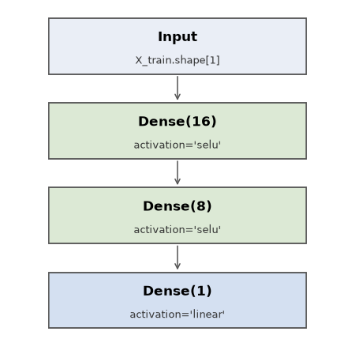

In [78]:
# [13번 문항] 여기에 답안코드를 작성하고 실행하세요.

model = tf.keras.models.Sequential([
    tf.keras.layers.Dense(16, activation='relu', input_shape=(X_train.shape[1],)),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

estop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
cb_list = [estop]

model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

history = model.fit(X_train, y_train, epochs=100, batch_size=32, validation_split=0.2, callbacks=cb_list)

print(model.count_params())

Epoch 1/100


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.0000e+00 - loss: -220.3911 - val_accuracy: 0.0000e+00 - val_loss: -532.3891
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0000e+00 - loss: -959.5980 - val_accuracy: 0.0000e+00 - val_loss: -1441.2084
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0000e+00 - loss: -2188.4583 - val_accuracy: 0.0000e+00 - val_loss: -3089.7224
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0000e+00 - loss: -4447.7998 - val_accuracy: 0.0000e+00 - val_loss: -5913.4360
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0000e+00 - loss: -8297.7764 - val_accuracy: 0.0000e+00 - val_loss: -10525.9453
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.0000e+00 - loss: -14655.2969 - val_accuracy: 0.0000e+00 - val_loss: -18114.8184
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.0000e+00 - loss: -24624.2266 - val_accuracy: 0.0000e+00 - val_loss: -29858.1621
Epoch 8/

<details><summary>힌트 1단계 (접근 방향) - 13번 문항</summary>

가이드를 위에서부터 코드로 옮기세요: 모델 구조 -> 콜백 -> compile -> fit. **개념** `shape[0]` 은 행 수, `shape[1]` 은 열 수입니다. EarlyStopping 의 patience 는 성능이 나아지지 않아도 참고 기다리는 epoch 수입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 13번 문항</summary>

사용할 도구: `Sequential`, `Dense`, `Dropout`, `EarlyStopping`, `model.compile`, `model.fit`.

</details>

<details><summary>힌트 3단계 (코드 구조) - 13번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
model = ____([
    ____(shape=(X_train.shape[____],)),
    ____(____, activation='____'),
    ____(____, activation='____'),
    ____(____, activation='____')
])

estop = ____(monitor='____', patience=____, restore_best_weights=True)
cb_list = [estop]

# ▷ 실행해서 결과 확인 — `compile` 사용

# ▷ `history` 에 결과를 저장 — `fit` 사용

# [model] 결과 확인
# ▷ 실행해서 결과 확인 — `count_params` 사용
```
- 참고 문서: <https://www.tensorflow.org/api_docs/python/tf/keras/models/Sequential>
- 참고 문서: <https://www.tensorflow.org/api_docs/python/tf/keras/Input>
- 참고 문서: <https://www.tensorflow.org/api_docs/python/tf/keras/layers/Dense>

</details>

### **14. 앞서 만든 딥러닝 모델의 일반화 성능을 평가하려고 합니다. matplotlib 라이브러리를 활용해서, 학습 Loss와(과) 검증 Loss의 변화를 그래프로 시각화하세요.**

<sub>학습 목표: 학습 기록으로 딥러닝 모델의 학습 과정과 성능을 분석할 수 있다 | 역량: AM5 딥러닝 학습 결과 분석 | 기술: matplotlib(plot, title, xlabel, ylabel) · TensorFlow(Keras)(history) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 1번 `plt` · 13번 `history`
- 학습 Loss 과 검증 Loss 를 한 그래프(1개)에 함께 그리세요
- 그래프의 제목은 'Model Loss' 로, X축 이름은 'Epochs', Y축 이름은 'Loss' 로 표시하세요
- legend 에는 'train', 'val' 를 쓰세요
- 아래 코드 셀의 빈칸 `< blank14_1 >`, `< blank14_2 >` 를 채우고 실행하세요
- 빈칸에 들어갈 내용(함수·인자·모듈 이름)을 코드 셀 맨 아래 `답안14_1`, `답안14_2` 변수에 각각 저장하세요
    - 예시) 답안14_0 = 'data'
- 같은 빈칸 표시가 여러 곳에 있으면 모두 같은 내용이 들어갑니다(정답은 한 번만 입력)
- 배점 : 10점

---

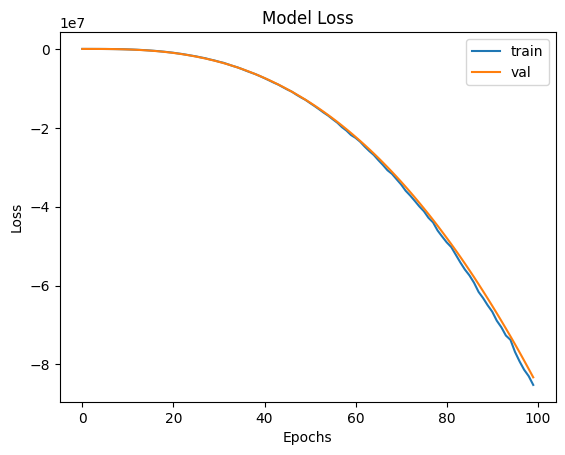

In [79]:
# [14번 문항] 아래 코드의 빈칸을 채우고 실행하세요.

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(['train', 'val'])
plt.show()

답안14_1 = 'plot'
답안14_2 = 'title'

<details><summary>힌트 1단계 (접근 방향) - 14번 문항</summary>

빈칸을 채워 코드를 완성한 뒤 실행하세요. 그래프 제목을 지정하는 matplotlib 함수입니다. **개념** plt.title 은 제목, plt.xlabel·ylabel 은 가로·세로축 이름, plt.legend 는 선 이름표입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 14번 문항</summary>

빈칸에 들어갈 것은 matplotlib.pyplot(그래프 꾸미기 함수) 쪽 이름입니다. 공식 문서 목록에서 찾아보세요: [matplotlib](https://matplotlib.org/stable/api/pyplot_summary.html)

</details>

<details><summary>힌트 3단계 (코드 구조) - 14번 문항</summary>

코드 구조입니다. `____` 자리에 들어갈 이름은 아래 공식 문서에서 확인하세요(오픈북 사이트).
```python
plt.____(history.history['loss'])
plt.____(history.history['val_loss'])
plt.____('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(['train', 'val'])
plt.show()

답안14_1 = '____'   # 빈칸 1에 넣은 이름
답안14_2 = '____'   # 빈칸 2에 넣은 이름
```
- 참고 문서: <https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.plot.html>
- 참고 문서: <https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.title.html>

</details>

### **모든 문항이 완료되었습니다. 수고하셨습니다.**
### 답안을 저장한 뒤 제출해 주시기 바랍니다.

In [80]:
# 전체 자동 채점 — 모든 문항을 푼 뒤 이 셀을 실행하세요. 정답 키는 압축·인코딩되어 있어 내용이 보이지 않습니다.
# (결과 변수 저장형은 지금 노트북에 남아 있는 변수로 채점합니다 — 앞 문항의 변수를 뒤에서 덮어쓰지 마세요)
import base64 as _b64, json as _json, zlib as _zlib
_정답키 = _json.loads(_zlib.decompress(_b64.b64decode("eNq1Vs2O2yAQfhWLSxIpQsaO47jS3rqV9tr2UCmKELHJxgoG1+DNWqu9V+q5j9Knah+iQLIJ+XO83fZkD8x838B8A0yfABfgnYeGHljlPNO/IBUZBdp+IJU2ec2YNkqRcyW1HUFfm+mSpitjTp+AMkFEKpwXpaiUCS1EVjNqxguiSiYUy+ewbMyfmSYsJyYYlMzaX00Gz0Nvi0Ufc6m59AQnBX3xe55ZD5tu4KRr0txlCzKiCOiQ7ymHjdwnIZekpCfzlojVZmCK4iAceiicuZmXNhn71XYlap71F0wQ1ecl5ITLujB/RJKqIk3fgEJJGU0VzlRTUtnv8bqY06o38PKFt9SOSlXWb+j1Djy1B2WSeps5O3ZjqQaDwdALBm6yYz8OkjiAkR5TgpkR6Cehu6fhv5BAShgzgYuap3YX67kput3o1ZpU9yZAE1ZiLbey46lg5j943ioh3O/nOci5eHzRkYP4aKZu8Z2ihZlpjPnhFn9SIl3hz4KDjugPuWA5/48EkiqscsUo2Pk7RRg5RdBiWVNX27++//z949vojLxJmtLSUE5HCE5muyL70Edojx61tg3WSysPwMev6Z1N+JUG2nHsu2g80mmhwOkiIwjMSLq6GL2VzFQX5KNY47sMvLUJLXTXTrTObe24dWjvySgOo3CcwGBXrgjGUTRy9TBurxgnb6gXd487LrZgJy5ONvF1dcYYHaQUHOkT3Gv9Z3VR5FQCR6ivJAnaSbJKlHiRV1K9gSNs58j5QpxHn1ws2hesi59nf1e0L1hVJOeg7aJ8IWjzaTrgNCc4jPJzRI6ewyRqcd9wOu4JSi73rN4bt0O36UC9qfRxAE3/Dg56KUSjJJi4Wk2ulzg5U4d9gREMLx6kyL+OjvwDeOQf4fswCg4IfDR2GFAHBtTOYO+nuixZYy+os1pFQQee4NpKgnjSspTwYj/odyJl58A7tMMmtk3ESz0gqgZclpnFgKm+IBQuSUUK2T+Q1SiJLwdrifenzFuIymNezr0NGCMNraS5Mczh32cDiLFJCGPv5sbrvadc0t7sULyXObZLgJvkpj1ainQpezM3HPm+K3zU4Q2BRkfH9PEzAtgX0HnFdMMP2vE3TyCXYPYHyEfBCA==")).decode("utf-8"))


def _같음(a, b, tol=0):
    try:
        if a is None or b is None:
            return a is None and b is None
        if isinstance(b, str) or isinstance(a, str):
            return str(a).strip().strip("'\"").replace(" ", "").lower() == str(b).strip().strip("'\"").replace(" ", "").lower()
        if isinstance(b, (list, tuple)):
            return len(a) == len(b) and all(_같음(x, y, tol) for x, y in zip(a, b))
        return abs(float(a) - float(b)) <= float(tol) + 1e-9
    except Exception:
        return False


def _검사(g, c):
    if c["t"] in ("ast_call", "ast_import", "ast_count", "src_contains"):
        return _코드검사(g, c)
    try:
        t, obj = c["t"], g.get(c.get("name"))
        if t == "exists":
            return c["name"] in g
        if t == "shape":
            return tuple(obj.shape) == tuple(c["value"])
        if t == "len":
            return len(obj) == c["value"]
        if t == "cols_have":
            return all(x in obj.columns for x in c["cols"])
        if t == "cols_lack":
            return all(x not in obj.columns for x in c["cols"])
        if t == "no_na":
            import pandas as _pd
            return int(_pd.DataFrame(obj).isna().sum().sum()) == 0
        if t == "all_numeric":
            import pandas as _pd
            d = _pd.DataFrame(obj)
            return all(_pd.api.types.is_numeric_dtype(d[x]) or _pd.api.types.is_bool_dtype(d[x]) for x in d.columns if x not in c.get("except", []))
        if t == "expr":
            return _같음(eval(c["expr"], g), c["value"], c.get("tol", 0))
        if t == "attr":
            return _같음(getattr(obj, c["attr"]), c["value"], c.get("tol", 0))
        if t == "has_attr":
            return hasattr(obj, c["attr"])
    except Exception:
        return False
    return False


_채점기록 = {}


def 채점(번호=None):
    """번호를 주면 그 문항만, 없으면 전체 문항을 채점해 점수를 보여 줍니다.
    결과 변수 저장형은 그 문항 바로 뒤의 `채점(번호)` 결과를 기억해 둡니다(뒤 문항이 같은 변수를 바꿀 수 있어서)."""
    g = globals()
    대상 = [k for k in _정답키 if 번호 is None or k["no"] == 번호]
    점수 = 0.0
    for k in 대상:
        if k["kind"] in ("var", "code"):
            지금 = (k["kind"] == "code" or k["var"] in g) and all(_검사(g, c) for c in k["checks"])
            if 번호 is not None:
                _채점기록[k["no"]] = 지금
            ok = _채점기록.get(k["no"], 지금) if 번호 is None else 지금
            무엇 = "작성한 코드" if k["kind"] == "code" else f"변수 `{k['var']}`"
        else:
            v = g.get(k["var"])
            ok = v is not None and any(_같음(v, a, k.get("tol", 0)) for a in k["accept"])
            무엇 = f"`{k['var']}`"
        점수 += k["points"] if ok else 0
        print(f"{'✅' if ok else '❌'} {k['no']}번 ({k['points']:g}점) — {무엇} {'정답' if ok else '다시 확인하세요'}")
    if 번호 is None:
        print(f"\n총점: {점수:g} / {sum(k['points'] for k in _정답키):g}")
        globals()["_최종점수"] = 점수
    return 점수


def _셀기록(g, no=None):
    import ast as _ast
    out = []
    for s in (g.get("In") or g.get("_ih") or []):
        if not isinstance(s, str) or "_정답키" in s:
            continue
        if no is not None and f"[{no}번 문항]" not in s:
            continue
        try:
            body = "\n".join(l for l in s.splitlines() if not l.strip().startswith(("#", "%", "!")))
            out.append((_ast.parse(body), body))
        except SyntaxError:
            pass
    return out


def _코드검사(g, c):
    import ast as _ast
    no = c.get("q")
    def _값(n):
        try:
            return _ast.literal_eval(n)
        except Exception:
            try:
                return _ast.unparse(n)
            except Exception:
                return None
    for tree, _ in _셀기록(g, no):
        for nd in _ast.walk(tree):
            if c["t"] == "ast_call" and isinstance(nd, _ast.Call):
                f = nd.func
                name = f.attr if isinstance(f, _ast.Attribute) else (f.id if isinstance(f, _ast.Name) else None)
                if name != c["func"]:
                    continue
                kws = {k.arg: _값(k.value) for k in nd.keywords if k.arg}
                if all(k in kws and _같음(kws[k], v) for k, v in (c.get("kwargs") or {}).items()) and len(nd.args) >= (c.get("n_pos") or 0):
                    return True
            if c["t"] == "ast_import" and isinstance(nd, (_ast.Import, _ast.ImportFrom)):
                if isinstance(nd, _ast.Import) and any(a.name == c["module"] and (c.get("alias") is None or a.asname == c.get("alias")) for a in nd.names):
                    return True
                if isinstance(nd, _ast.ImportFrom) and c.get("name") and nd.module == c["module"] and any(a.name == c["name"] for a in nd.names):
                    return True
    if c["t"] == "ast_count":
        n = sum(1 for tree, _ in _셀기록(g, no) for nd in _ast.walk(tree) if isinstance(nd, _ast.Call)
                and ((nd.func.attr if isinstance(nd.func, _ast.Attribute) else getattr(nd.func, "id", None)) == c["func"]))
        return c.get("min", 0) <= n <= c.get("max", 10 ** 6)
    if c["t"] == "src_contains":
        src = "\n".join(b for _, b in _셀기록(g, no))
        toks = [c["text"]] if isinstance(c["text"], str) else c["text"]
        return all(t in src for t in toks)
    return False


_점수 = 채점()


✅ 1번 (5점) — 작성한 코드 정답
✅ 2번 (5점) — 변수 `data` 정답
✅ 3번 (5점) — 작성한 코드 정답
✅ 4번 (5점) — `답안4` 정답
✅ 5번 (6점) — 변수 `data_temp` 정답
✅ 6번 (6점) — 변수 `data_na` 정답
✅ 7번 (2점) — `답안7_1` 정답
✅ 7번 (2점) — `답안7_2` 정답
✅ 7번 (2점) — `답안7_3` 정답
✅ 8번 (6점) — 변수 `X_valid` 정답
✅ 9번 (6점) — `답안9` 정답
✅ 10번 (10점) — `답안10` 정답
✅ 11번 (10점) — `답안11` 정답
✅ 12번 (10점) — `답안12` 정답
✅ 13번 (10점) — 변수 `model` 정답
✅ 14번 (5점) — `답안14_1` 정답
✅ 14번 (5점) — `답안14_2` 정답

총점: 100 / 100
